# MethaneSET · EMIT

Hyperspectral scenes of EMIT: 285 bands at 60 m, four precomputed matched-filter retrievals and two independent plume masks per granule, from IMEO and Carbon Mapper. This tutorial opens the catalog, looks at one scene and compares the four retrievals on the same scale.

In [1]:
HF_TOKEN = ""  #@param {type:"string"}

# Anonymous Hugging Face reads share the rate limit of the whole Colab fleet. With a free
# account token pasted above the limit is yours, and the notebook stops hitting 429.
# Create one at https://huggingface.co/settings/tokens (read access is enough).
if HF_TOKEN:
    import os
    os.environ["HF_TOKEN"] = HF_TOKEN
    try:
        from huggingface_hub import login
        login(HF_TOKEN, add_to_git_credential=False)
        print("Using your Hugging Face token.")
    except Exception as exc:
        print("Token not accepted:", exc)

In [2]:
# Setup
import os, json, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from rasterio.windows import Window
import rasterio

warnings.filterwarnings("ignore", category=rasterio.errors.NotGeoreferencedWarning)

if not Path("common.py").exists():
    import urllib.request
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/IPL-UV/taco-methaneset/main/methaneset-codes/notebooks/common.py",
        "common.py")

try:
    import tacoreader
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "tacoreader>=2.4,<3",
                           "rasterio", "matplotlib", "pandas", "pyarrow", "scipy", "scikit-learn"])

import common as C
C.style()
import matplotlib as _mpl
_mpl.rcParams["figure.dpi"] = _mpl.rcParams["savefig.dpi"] = 70

C.versions()
print("dataset version:", C.dataset_version("methaneset-emit"))

tacoreader 2.4.21
rasterio   1.4.4
numpy      2.4.6
torch      2.7.0+cu126
colab      False
[common] methaneset-emit: local
dataset version: 1.3.0


In [3]:
def parse_json(x):
    if isinstance(x, str):
        return json.loads(x)
    return x


def points(txt):
    m = re.findall(r"(-?\d+\.\d+) (-?\d+\.\d+)", str(txt))
    return [(float(a), float(b)) for a, b in m] or []

## The catalog

721 granules, one row each. `level0` holds the masks, the emission rates and the bitmaps, so most questions are answered without opening a raster.

In [4]:
ds = C.load("methaneset-emit")
df = ds.data.to_pandas()

print(f"{len(df)} granules | {len(df.columns)} columns")

# namespace inventory
ns = df.columns.str.split(":").str[0].value_counts().sort_index()
print("\nColumns per namespace:")
print(ns.to_string())

# table of the 10 sheets
s = ds.read(int(df[df["detection:n_imeo"] > 0].index[0]))
C.layers(s)

[common] methaneset-emit: local


721 granules | 83 columns

Columns per namespace:
detection    25
emit          3
id            1
internal      1
match         6
meteo         5
radiance      4
selection    19
sensor        6
site          1
spatial       6
target        5
type          1


,sheet,shape,dtype,nodata,count
0,radiance.tif,"(1280, 1242)",float32,-9999.0,285
1,latlon.tif,"(1280, 1242)",float32,NaN,2
2,glt.tif,"(1877, 2268)",int32,0.0,2
3,elevation.tif,"(1280, 1242)",float32,NaN,1
4,wind.tif,"(1280, 1242)",float32,NaN,2
5,mf.tif,"(1280, 1242)",float32,-9999.0,1
6,rmf.tif,"(1280, 1242)",float32,-9999.0,1
7,mag1c.tif,"(1280, 1242)",float32,-9999.0,1
8,wwmf.tif,"(1280, 1242)",float32,-9999.0,1
9,plume_imeo.tif,"(1280, 1242)",uint64,0.0,2


## One scene

The granule with the strongest IMEO plume. The panel reads three radiance bands into a true colour composite, the spectrum of one plume pixel against one background pixel, the wind field stored with the granule and the elevation.

In [5]:
# strongest plume by IMEO max flux
idx = int(df["detection:imeo_flux_max"].idxmax())
row = df.loc[idx]
s = ds.read(idx)

mask = C.read(s, "plume_imeo.tif", bands=1)
rs, cs = C.crop_around(mask, pad=60)

# RGB: only 3 bands (bug fix)
rad = C.read(s, "radiance.tif", bands=(36, 24, 13), window=(rs, cs))
rgb = C.to_rgb(rad, (0, 1, 2))

# wind and elevation in the same window
wind = C.read(s, "wind.tif", window=(rs, cs))
elev = C.read(s, "elevation.tif", bands=1, window=(rs, cs))

# spectrum: one plume pixel and one nearby background pixel
bits = parse_json(row["detection:imeo_bits"])
plume_mask = C.bit_layer(mask, 1)[rs, cs]
ys, xs = np.where(plume_mask)
py, px = int(np.median(ys)), int(np.median(xs))

# background pixel outside any mask, nearby
bg_candidates = [(y, x) for y in range(max(0, py - 30), min(plume_mask.shape[0], py + 31))
                 for x in range(max(0, px - 30), min(plume_mask.shape[1], px + 31))
                 if not plume_mask[y, x]]
by, bx = bg_candidates[len(bg_candidates) // 2] if bg_candidates else (py, px)

abs_py, abs_px = rs.start + py, cs.start + px
abs_by, abs_bx = rs.start + by, cs.start + bx

spec_plume = C.read(s, "radiance.tif", window=Window(abs_px, abs_py, 1, 1))[:, 0, 0]
spec_bg = C.read(s, "radiance.tif", window=Window(abs_bx, abs_by, 1, 1))[:, 0, 0]
wavelengths = 381.0 + np.arange(285) * ((2493.0 - 381.0) / 284.0)
swir_bands = np.array(C.emit_swir()) - 1  # 0-based

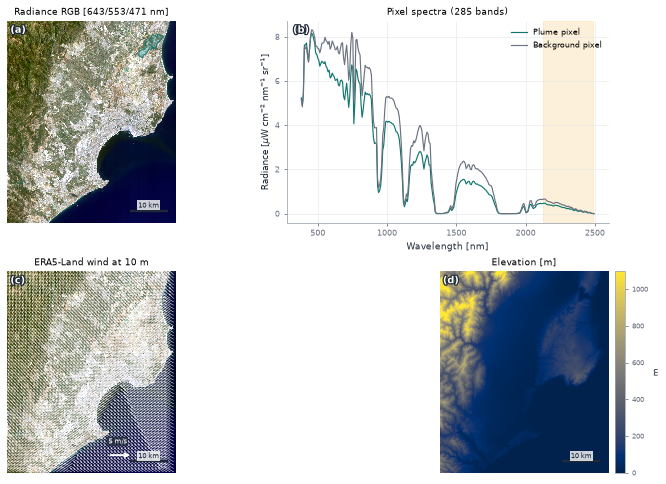

In [6]:
fig, axes = C.panels(4, rows=2, kind="image")

# (a) RGB
ax = axes[0]
ax.imshow(rgb)
C.overlay_mask(ax, plume_mask, which="imeo")
ax.set_title("Radiance RGB [643/553/471 nm]")
C.scalebar(ax, C.PIXEL_M["emit"])
C.panel_label(ax, "a")

# (b) spectrum
ax = axes[1]
C.ax_plot(ax)
ax.plot(wavelengths, spec_plume, color=C.PALETTE["imeo"], linewidth=1.2, label="Plume pixel")
ax.plot(wavelengths, spec_bg, color=C.PALETTE["muted"], linewidth=1.2, label="Background pixel")
ax.axvspan(wavelengths[swir_bands[0]], wavelengths[swir_bands[-1]], color=C.PALETTE["sun"], alpha=0.15)
ax.set_xlabel("Wavelength [nm]")
ax.set_ylabel("Radiance [$\\mu$W cm$^{-2}$ nm$^{-1}$ sr$^{-1}$]")
ax.set_title("Pixel spectra (285 bands)")
ax.legend(loc="upper right")
C.panel_label(ax, "b")

# (c) wind quiver on RGB
ax = axes[2]
ax.imshow(rgb)
step = 15
h, w = rgb.shape[0], rgb.shape[1]
yq, xq = np.mgrid[0:h:step, 0:w:step]
q = ax.quiver(xq, yq, wind[0][::step, ::step], -wind[1][::step, ::step],   # imshow flips the y axis
              color="white", scale=50, width=0.003)
ax.annotate("", xy=(0.74, 0.09), xytext=(0.60, 0.09), xycoords="axes fraction",
            arrowprops=dict(arrowstyle="->", color="white", lw=2))
ax.text(0.60, 0.14, "5 m/s", transform=ax.transAxes, fontsize=7, va="bottom", ha="left", color="white",
        bbox=dict(boxstyle="square,pad=0.15", facecolor=C.PALETTE["ink"], edgecolor="none", alpha=0.8))
ax.set_title("ERA5-Land wind at 10 m")
C.scalebar(ax, C.PIXEL_M["emit"])
C.panel_label(ax, "c")

# (d) elevation
ax = axes[3]
im = C.imshow_layer(ax, elev, kind="dem", title="Elevation [m]", label="m", px_m=C.PIXEL_M["emit"])
C.panel_label(ax, "d")

plt.show()

## The two masks

Each plume in a mask owns one bit, and a pixel holds the OR of the bits that cover it, so overlapping or nested plumes stack instead of hiding each other. The bit to id maps are in `detection:imeo_bits` and `detection:cm_bits`.

In [7]:
# build a label image: each bit gets its own color
bits_imeo = parse_json(row["detection:imeo_bits"])
bits_cm = parse_json(row["detection:cm_bits"])

rs2, cs2 = C.crop_around(mask, pad=12)
labels_imeo = np.zeros(mask.shape, dtype=np.int32)
for bit in bits_imeo:
    labels_imeo[C.bit_layer(mask, int(bit))] = int(bit)

mask_cm = C.read(s, "plume_cm.tif", bands=1)
labels_cm = np.zeros(mask.shape, dtype=np.int32)
for bit in bits_cm:
    labels_cm[C.bit_layer(mask_cm, int(bit))] = int(bit)

# qualitative colormap, background transparent
tab = plt.cm.tab20
qual_colors = [(0, 0, 0, 0)] + [tab((i - 1) % 20 / 19) for i in range(1, 65)]
cmap_bits = ListedColormap(qual_colors)

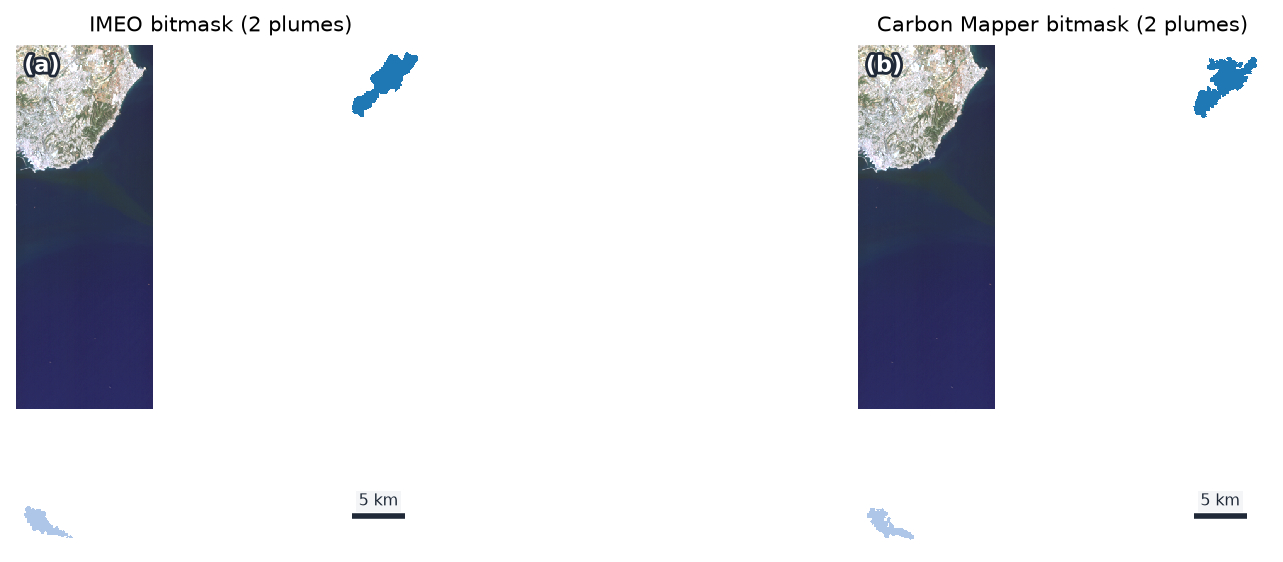

In [8]:
fig, axes = C.panels(2, dpi=C.DPI["hero"], rows=1, kind="image")

ax = axes[0]
ax.imshow(rgb[rs2, cs2], alpha=0.85)
ax.imshow(labels_imeo[rs2, cs2], cmap=cmap_bits, vmin=0, vmax=64, interpolation="nearest")
ax.set_title(f"IMEO bitmask ({len(bits_imeo)} plume{'s' if len(bits_imeo) > 1 else ''})")
C.scalebar(ax, C.PIXEL_M["emit"])
C.panel_label(ax, "a")

ax = axes[1]
ax.imshow(rgb[rs2, cs2], alpha=0.85)
ax.imshow(labels_cm[rs2, cs2], cmap=cmap_bits, vmin=0, vmax=64, interpolation="nearest")
ax.set_title(f"Carbon Mapper bitmask ({len(bits_cm)} plume{'s' if len(bits_cm) > 1 else ''})")
C.scalebar(ax, C.PIXEL_M["emit"])
C.panel_label(ax, "b")

plt.show()

## The four retrievals

`mf` is the classical matched filter, `rmf` adds the per-pixel albedo correction in a single pass, `mag1c` is the iterative sparse version and `wwmf` runs the same filter over 1000-2500 nm without the two water-vapour windows. All four are in ppm m on one colour scale, so the panels are comparable.

In [9]:
# use the strongest plume scene for the matched-filter comparison
idx = int(df["detection:imeo_flux_max"].idxmax())
row = df.loc[idx]
s = ds.read(idx)
mask = C.read(s, "plume_imeo.tif", bands=1)
mask_cm = C.read(s, "plume_cm.tif", bands=1)
rs, cs = C.crop_around(mask, pad=60)
m_i = C.bit_layer(mask, 1)

# Carbon Mapper plume paired with the strongest IMEO plume, if any
bits_imeo = parse_json(row["detection:imeo_bits"])
bits_cm = parse_json(row["detection:cm_bits"])
pairs = parse_json(row["match:pairs"])
m_c = np.zeros_like(mask, dtype=bool)
for p in pairs:
    if p["imeo"] == bits_imeo["1"]:
        _bit = next((int(b) for b, name in bits_cm.items() if name == p["cm"]), None)
        if _bit is not None:
            m_c = C.bit_layer(mask_cm, _bit)
        break

# read the four retrievals in the same window
mf = C.read(s, "mf.tif", bands=1, window=(rs, cs))
rmf = C.read(s, "rmf.tif", bands=1, window=(rs, cs))
mg = C.read(s, "mag1c.tif", bands=1, window=(rs, cs))
ww = C.read(s, "wwmf.tif", bands=1, window=(rs, cs))

# shared color scale across the four
# shared but robust: median of the three per-panel percentiles, so one map with
# extreme outliers does not flatten the other two
vmax = float(np.nanmedian([np.nanpercentile(x, 99.5) for x in (mf, rmf, mg, ww)]))

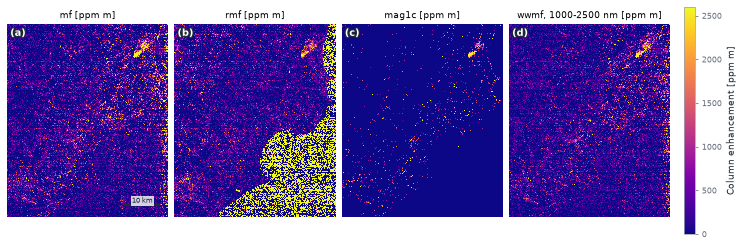

In [10]:
fig, axes = C.panels(4, rows=1, kind="image")
for ax, arr, title, letter in zip(axes, [mf, rmf, mg, ww],
                                  ["mf [ppm m]", "rmf [ppm m]", "mag1c [ppm m]",
                                   "wwmf, 1000-2500 nm [ppm m]"],
                                  ["a", "b", "c", "d"]):
    im = ax.imshow(arr, cmap=C.CMAPS["enh"], vmin=0, vmax=vmax)
    ax.set_title(title)
    if letter == "a":
        C.scalebar(ax, C.PIXEL_M["emit"])   # los cuatro paneles comparten ventana
    C.panel_label(ax, letter)

fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02, label="Column enhancement [ppm m]")
plt.show()

Against the IMEO masks the wide window raises the per-granule AUC from 0.715 to 0.739; against the Carbon Mapper masks it is level with the classical filter (0.700 against 0.701). `rmf` carries a bright residual at the lower edge of this granule: values above the shared scale saturate, and that is part of what the comparison shows.

Against the IMEO masks the wide window raises the per-granule AUC from 0.715 to 0.739; against the Carbon Mapper masks it is level with the classical filter (0.700 against 0.701). The numbers and the method are in the paper.